## Importance analysis with SHAP

<i> Classification -- multiclass

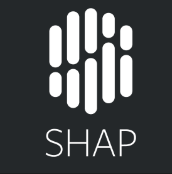


<i>

<br>

This notebook shows a basic analysis using feature importances (Shapley values.)

### <i> Imports

In [1]:
# pip install catboost
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import r2_score, mean_squared_error
from catboost import CatBoostRegressor
from sklearn import metrics

c:\Users\tuomas.valtanen\dataeng_advda2026_lectures\DataEngineering_AdvDA_2026\.venv\Lib\site-packages\xgboost\compat.py:105: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


### <i> Loading

In [2]:
# Load the dataframe
df = pd.read_csv("../Student_performance_data.csv")
df

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2387,3388,18,1,0,3,10.680555,2,0,4,1,0,0,0,3.455509,0.0
2388,3389,17,0,0,1,7.583217,4,1,4,0,1,0,0,3.279150,4.0
2389,3390,16,1,0,2,6.805500,20,0,2,0,0,0,1,1.142333,2.0
2390,3391,16,1,1,0,12.416653,17,0,2,0,1,1,0,1.803297,1.0


--- 

## Model training and Shap importance analysis

In [3]:
from xgboost import XGBClassifier

# Split features and target.
X = df.drop(columns=["GradeClass","GPA", "Ethnicity", "StudentID"])
y = df["GradeClass"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = XGBClassifier(
    n_estimators=100,
    objective="multi:softprob",
    num_class=5,
    eval_metric="mlogloss",
    verbosity=0,
    random_state=42
)

model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)


In [4]:
from sklearn import metrics
import numpy as np

# Metrics
accuracy = metrics.accuracy_score(y_test, y_pred)
precision = metrics.precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = metrics.recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = metrics.f1_score(y_test, y_pred, average="weighted", zero_division=0)

roc_auc = metrics.roc_auc_score(
    y_test,
    y_prob,
    multi_class="ovr",
    average="weighted"
)

mae = metrics.mean_absolute_error(y_test, y_pred)

# Confusion matrix
cm = metrics.confusion_matrix(y_test, y_pred)

# Classification report
report = metrics.classification_report(
    y_test,
    y_pred,
    zero_division=0
)

print("--------------------------")
print("CLASSIFICATION METRICS")
print("--------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")


print("\nClassification Report:")
print(report)

--------------------------
CLASSIFICATION METRICS
--------------------------
Accuracy:  0.6806
Precision: 0.6854
Recall:    0.6806
F1-score:  0.6816
ROC-AUC:   0.8839

Classification Report:
              precision    recall  f1-score   support

         0.0       0.38      0.24      0.29        21
         1.0       0.51      0.48      0.50        54
         2.0       0.46      0.54      0.50        78
         3.0       0.44      0.46      0.45        83
         4.0       0.91      0.88      0.90       243

    accuracy                           0.68       479
   macro avg       0.54      0.52      0.53       479
weighted avg       0.69      0.68      0.68       479



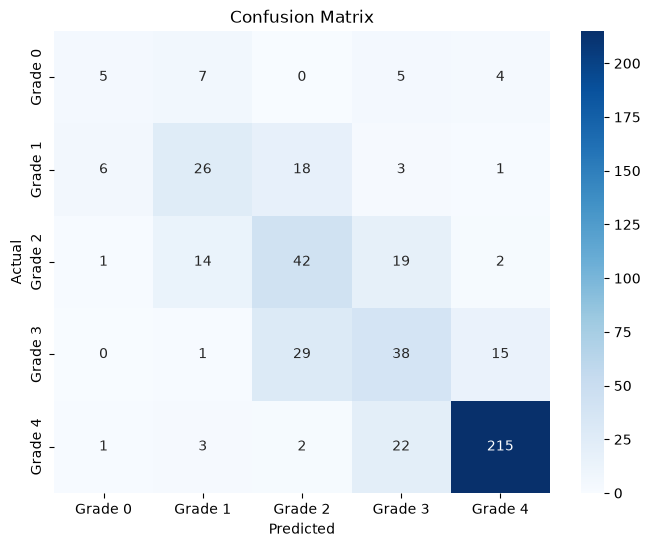

In [5]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Grade 0","Grade 1","Grade 2","Grade 3","Grade 4"],
    yticklabels=["Grade 0","Grade 1","Grade 2","Grade 3","Grade 4"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

---

### <i> Retrieving shap values

In [6]:
# Generate SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)
print("Shap values created")

Shap values created


In [7]:
# Get number of classes
n_classes = shap_values.shape[2]

### <i> Bar plot

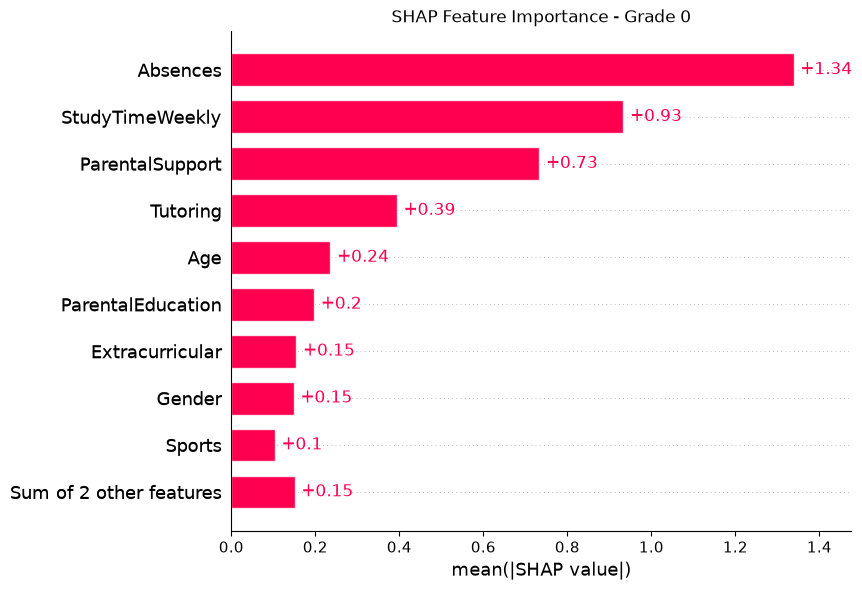

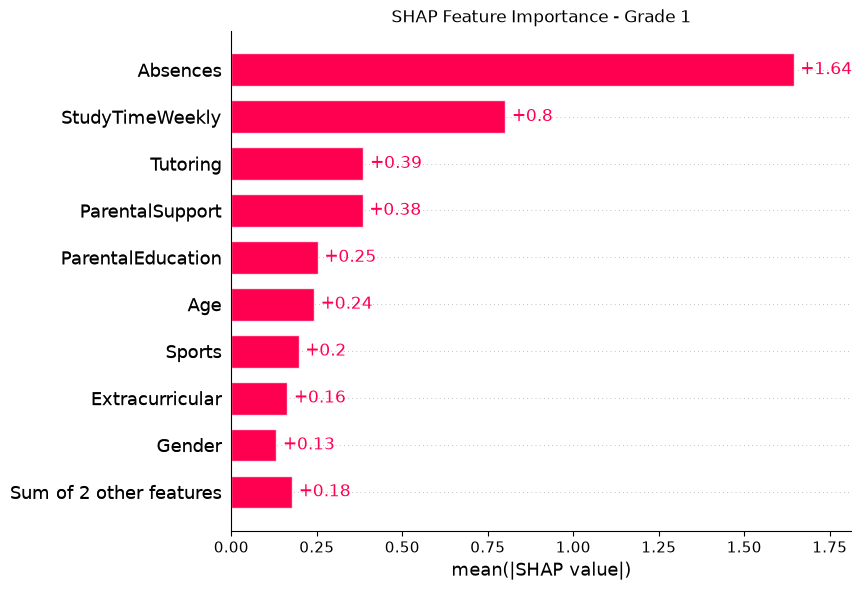

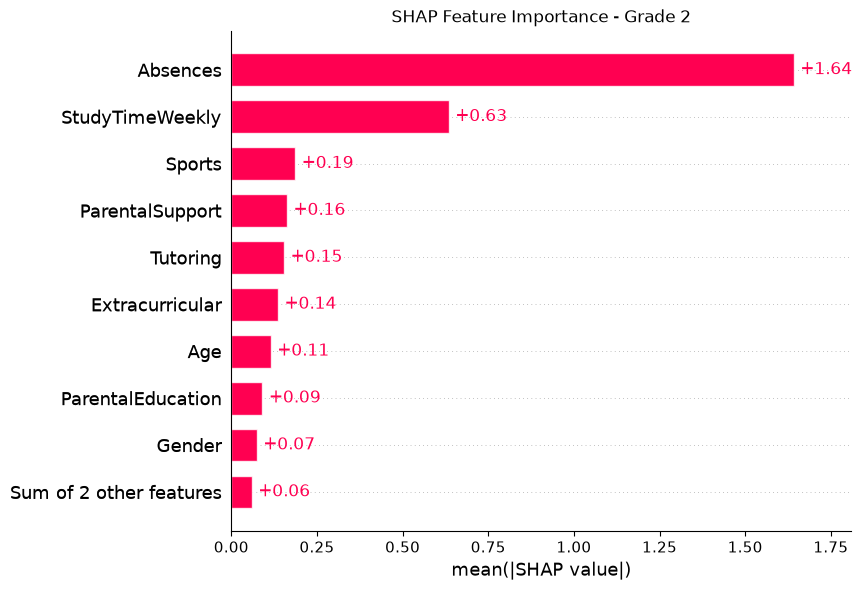

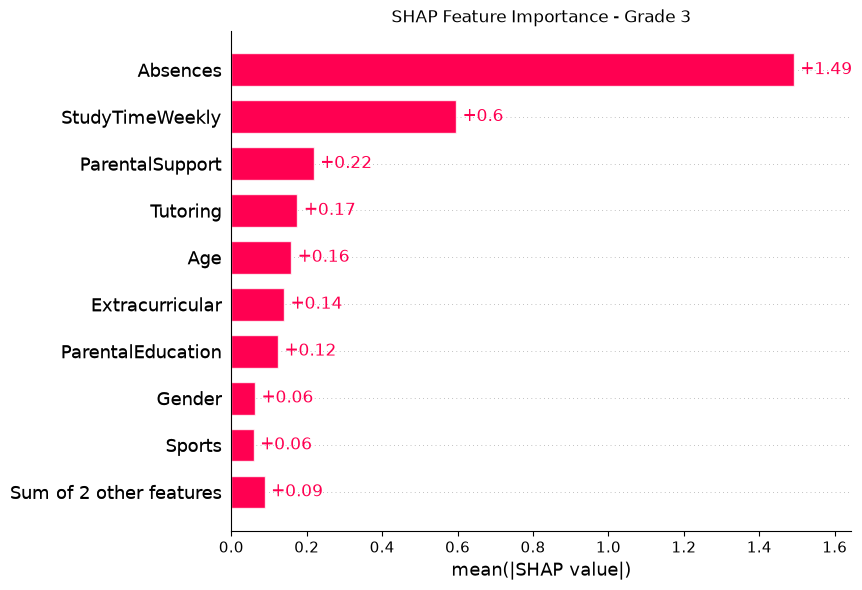

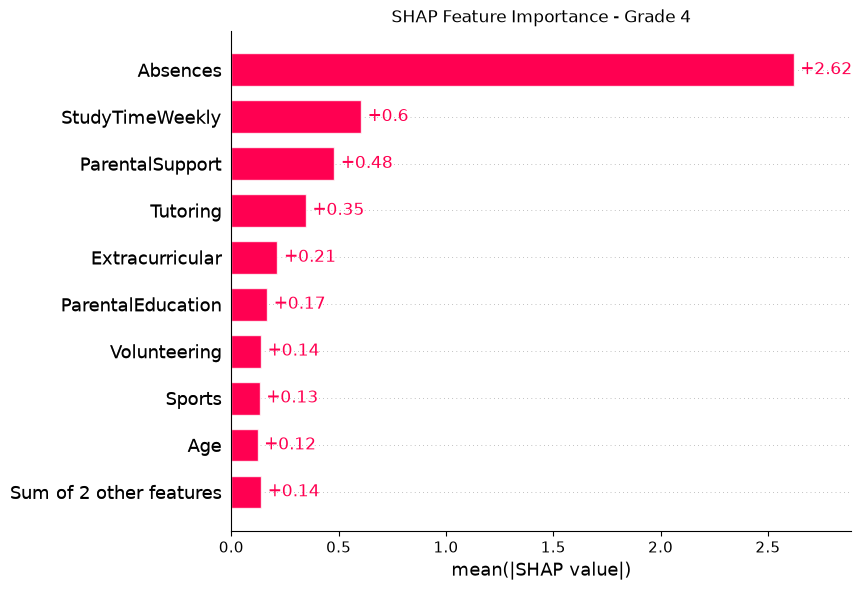

In [8]:
# Iterating through the classes of barplots.
for index in range(n_classes):

    # Select class 5
    shap_class = shap_values[:, :, index]

    plt.title(f"SHAP Feature Importance - Grade {index}")

    # Create cohorts from actual target labels
    shap.plots.bar(shap_class)

### <i> Beeswarm plot

(479, 11, 5)


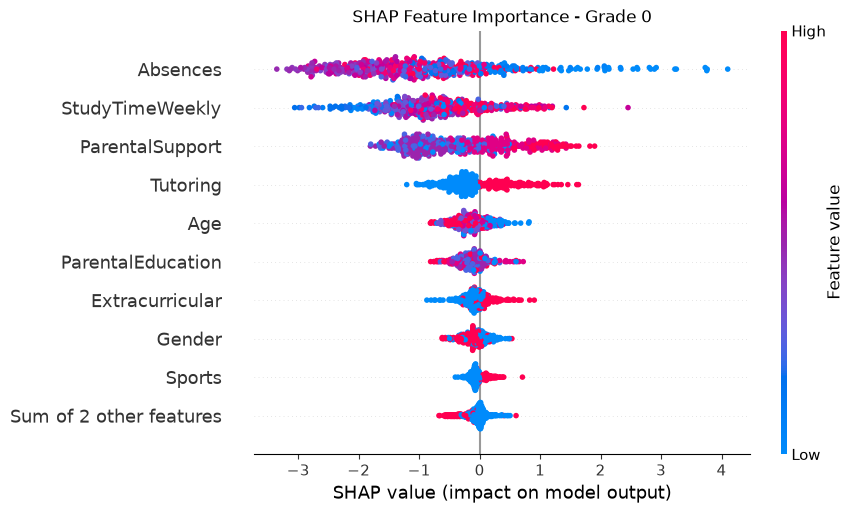

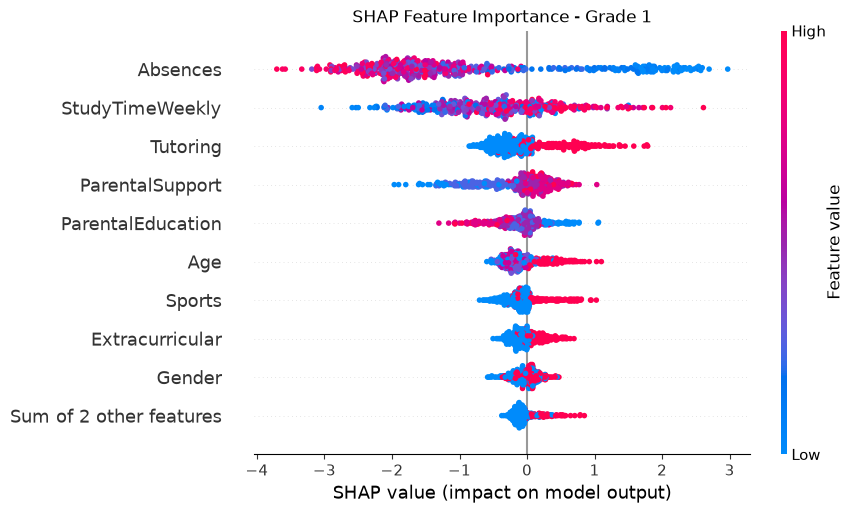

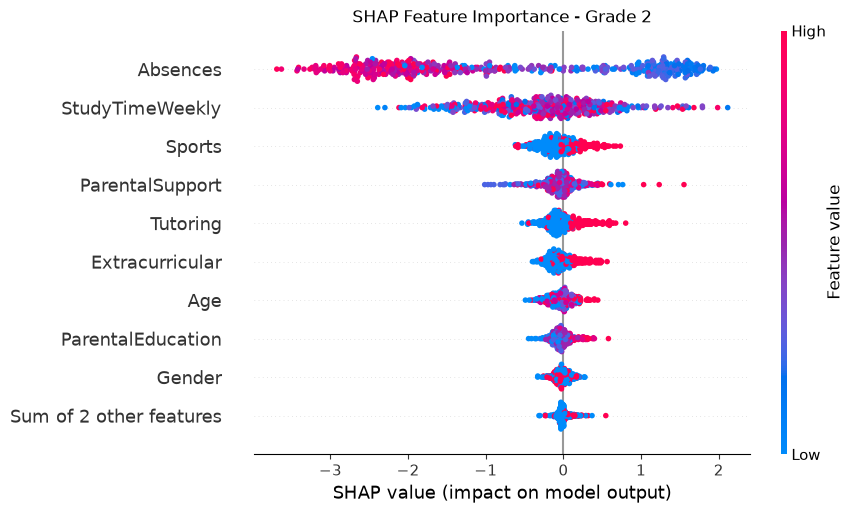

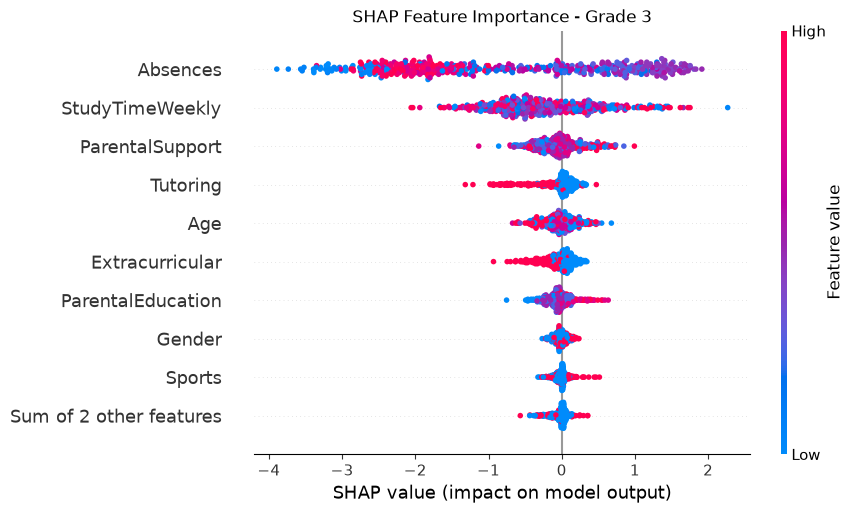

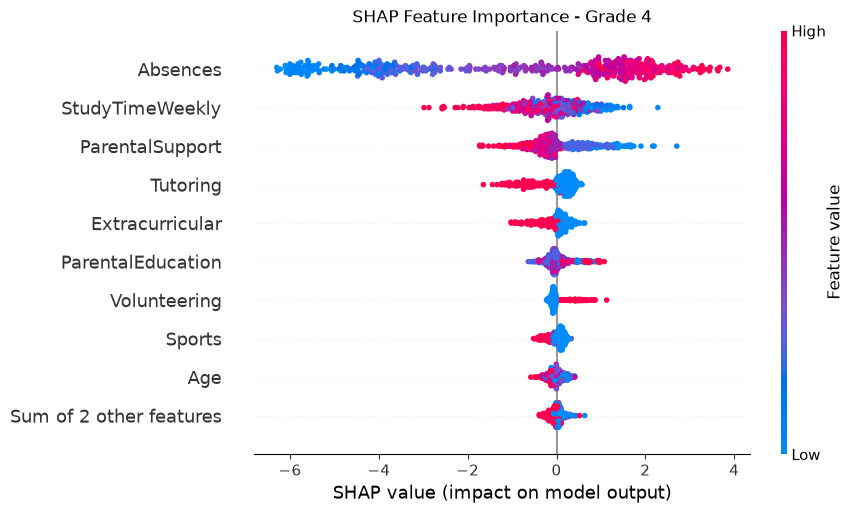

In [9]:
# Here we can tell we have a shape of 5, 
print(shap_values.shape)

# So we'll simply iterate through range(4) for each class.

for index in range(n_classes):

    # Select class 5
    shap_class = shap_values[:, :, index]

    plt.title(f"SHAP Feature Importance - Grade {index}")

    # Create cohorts from actual target labels
    shap.plots.beeswarm(shap_class)

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3>Observations</h3>

It appears that all feature importances believe `Absences` to be very useful in predicting the classification outcome.

`Volunteering` seems to be completely at the bottom of importances.  

</div>

### <i> Cohort bar plot



<i> Taken from [SHAP documentation](https://shap.readthedocs.io/en/latest/example_notebooks/api_examples/plots/bar.html)

This is a useful visual for classification!


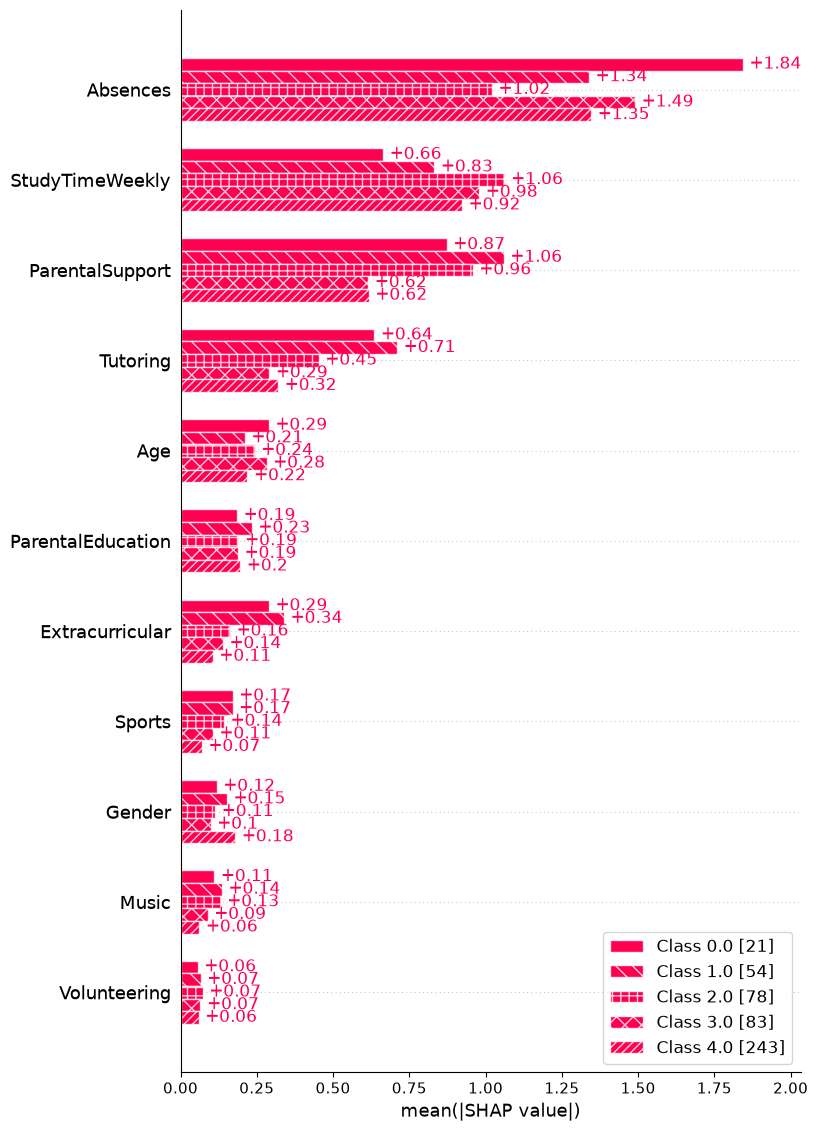

In [10]:
# Select class 0
shap_class = shap_values[:, :, 0]

# Create cohort labels
cohorts = [
    f"Class {value}" for value in y_test
]

# Calculate cohort importance
cohort_values = shap_class.cohorts(cohorts).abs.mean(0)

# Display all features
shap.plots.bar(
    cohort_values,
    max_display=X_test.shape[1]
)

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3>Observations</h3>

<i>

* Notice how class 3 doesn't consider `absences` to be as important as the lower and higher shap_classes. That is pretty interesting and might suggest some under-representation in the dataset.

* I would change the colors in this plot, but it's quite complicated and I didn't want to use the AI snippet that was given to me, since it seemed terribly complicated and over-engineered.


</div>

### <i> 

---

### <i> Isolating cases with SHAP

Below you'll find a very simple way to isolate cases with `SHAP` so you can inspect them more carefully.

In [11]:
# Get the prediction error.
residuals = y_test - y_pred

# Create a copy of the test dataframe
predictions_df = X_test.copy()

# Add actual and predicted values
predictions_df["Actual"] = y_test
predictions_df["Predicted"] = y_pred

# Add residuals
predictions_df["Residual"] = residuals

# Sort by the worst predictions
worst_predictions = predictions_df.sort_values("Residual", ascending=False)
worst_predictions

,Age,Gender,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,Actual,Predicted,Residual
2027,18,0,0,9.526766,28,1,3,0,0,0,0,4.0,0,4.0
2197,18,0,2,17.472676,0,0,0,0,1,0,0,4.0,1,3.0
2267,18,1,2,7.598010,0,1,3,0,0,0,0,4.0,1,3.0
2388,17,0,1,7.583217,4,1,4,0,1,0,0,4.0,1,3.0
1451,15,1,3,17.246698,14,0,3,0,0,1,0,4.0,2,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2303,15,0,2,2.119118,13,1,3,1,0,0,0,0.0,3,-3.0
2266,18,0,3,4.750322,16,0,3,0,0,0,0,0.0,4,-4.0
2194,15,0,2,15.615710,26,0,3,1,0,0,0,0.0,4,-4.0
2284,16,0,1,13.673991,14,0,1,1,0,0,0,0.0,4,-4.0


<i> Use this to translate the worst_predictions index to the shapley_values index: 

In [12]:
# Find the index position in X_test from worst_predictions 
row_position = X_test.index.get_loc(2267)
print(f"The shap_value index is: {row_position}")

The shap_value index is: 50


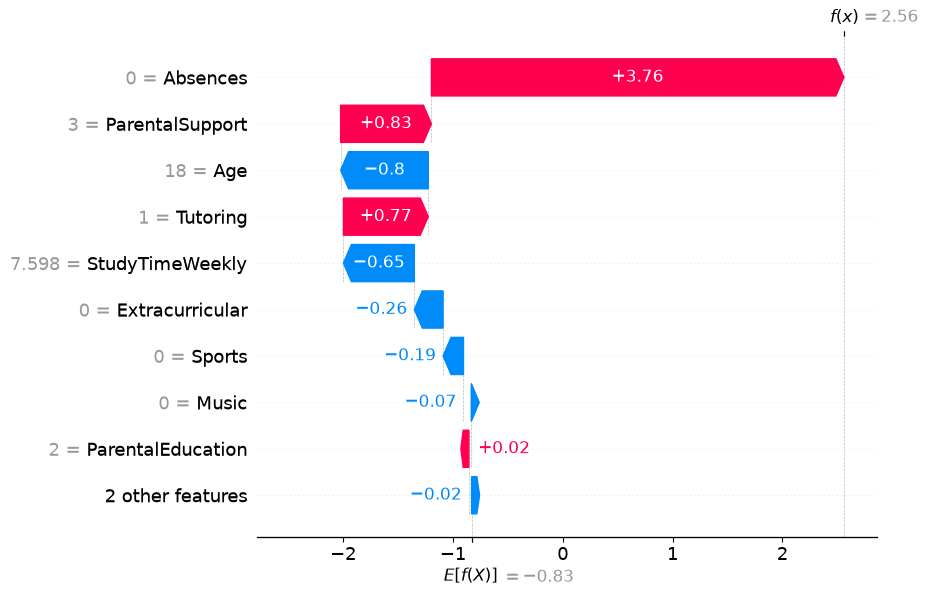

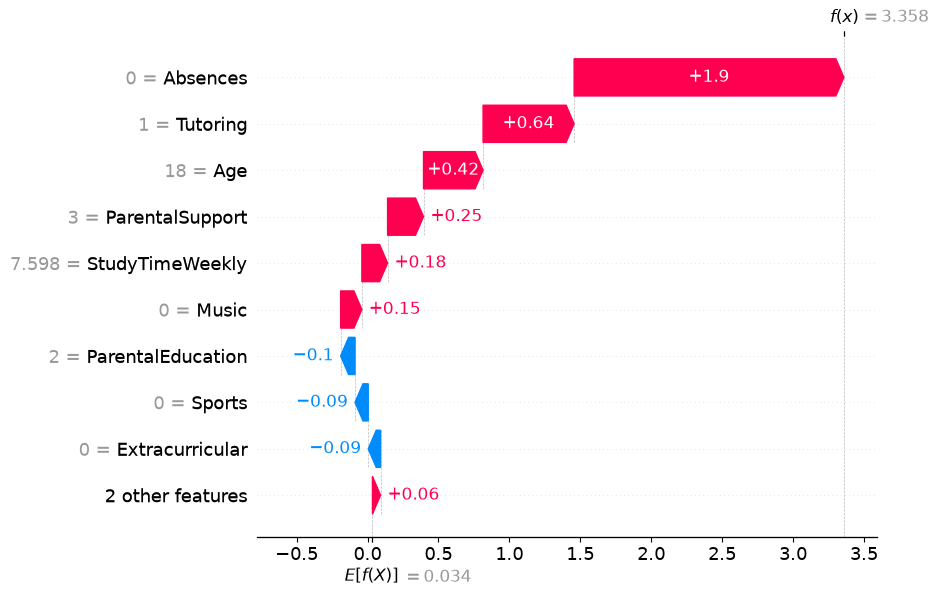

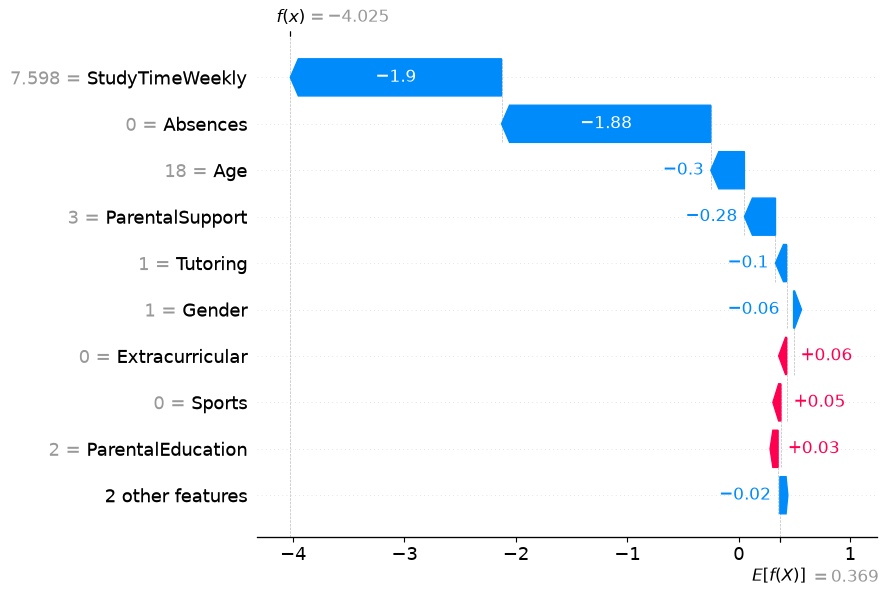

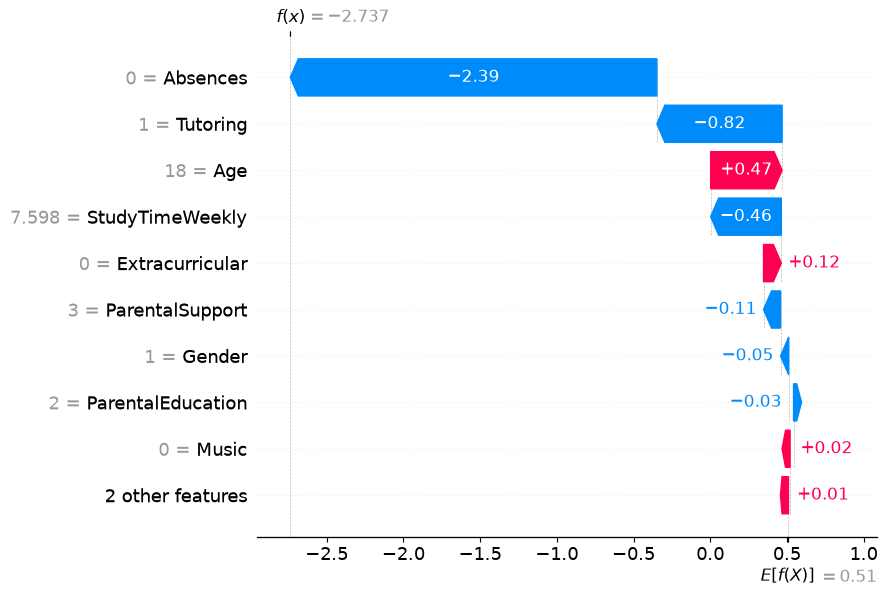

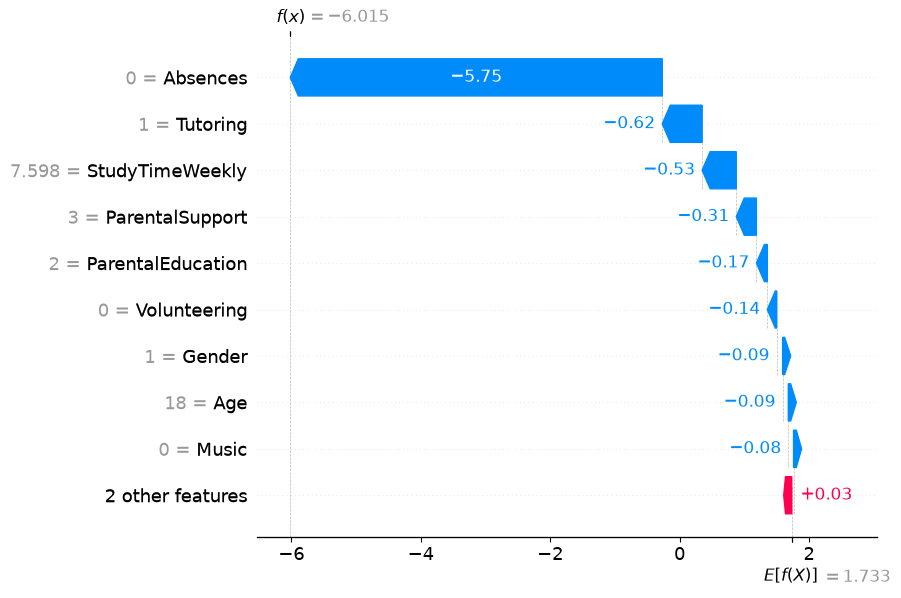

In [13]:
for index in range(n_classes):
    # Select class 0
    shap_class = shap_values[:, :, index]

    # Feel free to experiment!
    shap.plots.waterfall(shap_class[50])

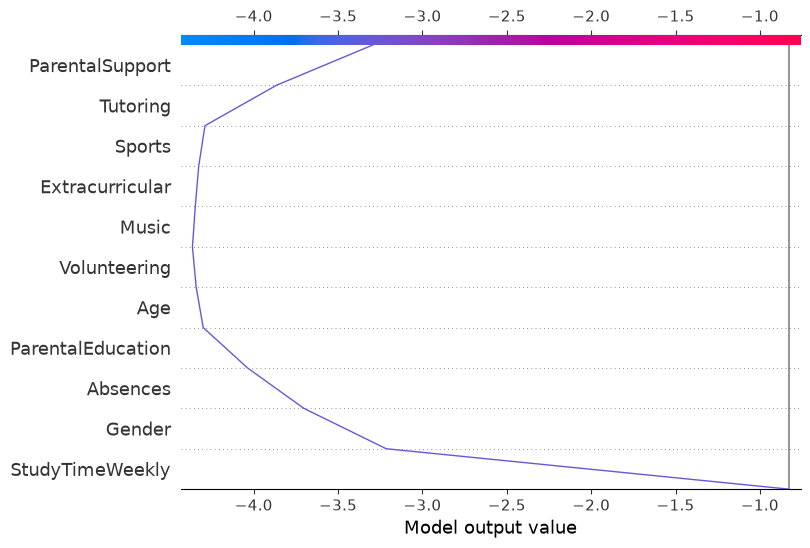

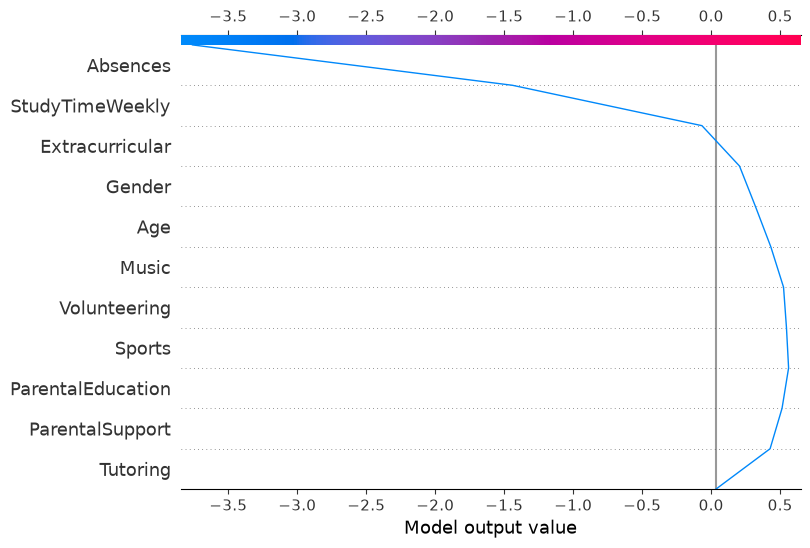

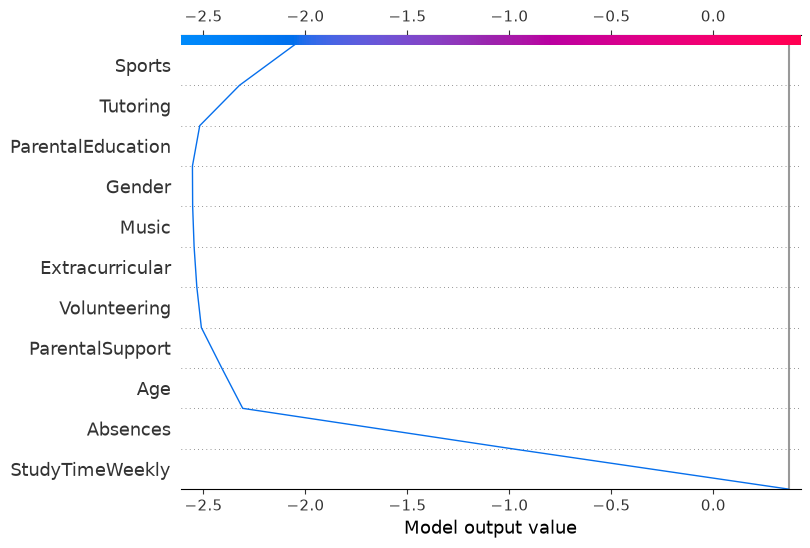

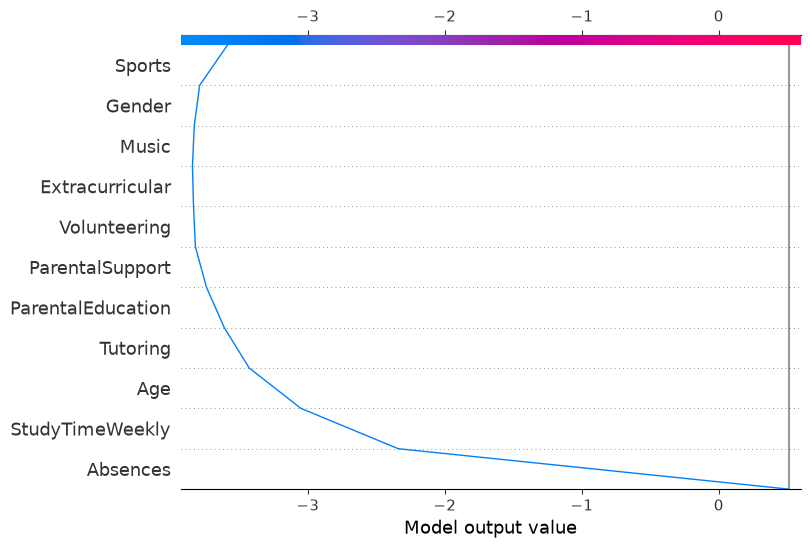

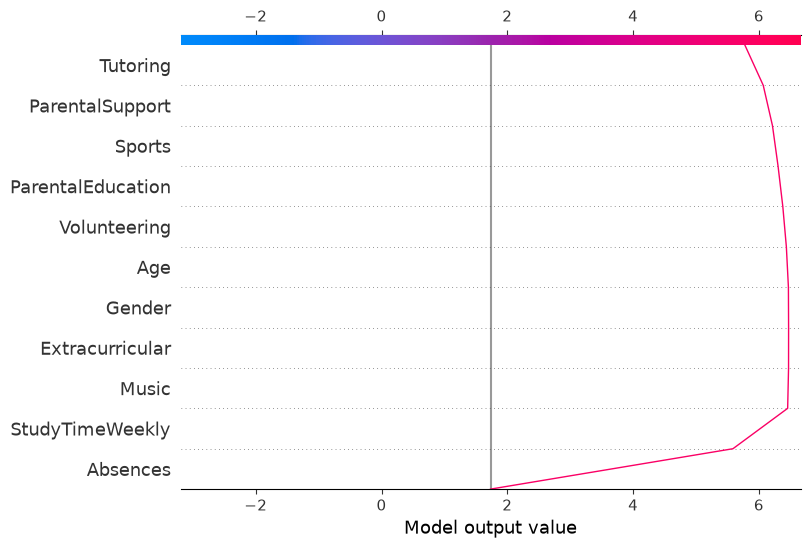

In [14]:

for index in range(n_classes):
    # Select class 0
    shap_class = shap_values[:, :, index]

    # Decision plot
    shap.decision_plot(
        shap_class.base_values[60],
        shap_class.values[60],
        feature_names=X_test.columns.tolist(),
        feature_order="hclust",
        show=True
    )



<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3>Observations</h3>

Each class appears to be predicting the worst residuals quite a bit differently! 

The features that affect the classification the most appear to be the roughly the same for each one.

</div>

---

## <i> Minor Optimizations

### <i> Interaction features

In [15]:
# Creating some interaction features

# Study habits
df["StudyPerAbsence"] = df["StudyTimeWeekly"] / (df["Absences"] + 1)

# Combined extracurricular engagement
df["ActivityCount"] = (
    df["Extracurricular"] +
    df["Sports"] +
    df["Music"] +
    df["Volunteering"]
)

# # Parental support relative to study time
# df["SupportStudyInteraction"] = (
#     df["ParentalSupport"] * df["StudyTimeWeekly"]
# )

# # Tutoring and parental support
# df["TutoringSupport"] = (
#     df["Tutoring"] * df["ParentalSupport"]
# )

# # Study time and tutoring
# df["StudyTutoring"] = (
#     df["StudyTimeWeekly"] * df["Tutoring"]
# )

# # Absence and study interaction
# df["AbsenceStudyInteraction"] = (
#     df["Absences"] * df["StudyTimeWeekly"]
# )


---

## <i> More optimized dataset

### <i> Re-training

In [16]:
from xgboost import XGBClassifier

# Split features and target.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = XGBClassifier(
    n_estimators=15,
    objective="multi:softprob",
    num_class=5,
    eval_metric="mlogloss",
    verbosity=0,
    random_state=42
)

model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)


In [17]:
from sklearn import metrics
import numpy as np

# Metrics
accuracy = metrics.accuracy_score(y_test, y_pred)
precision = metrics.precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = metrics.recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = metrics.f1_score(y_test, y_pred, average="weighted", zero_division=0)

roc_auc = metrics.roc_auc_score(
    y_test,
    y_prob,
    multi_class="ovr",
    average="weighted"
)

mae = metrics.mean_absolute_error(y_test, y_pred)

# Confusion matrix
cm = metrics.confusion_matrix(y_test, y_pred)

# Classification report
report = metrics.classification_report(
    y_test,
    y_pred,
    zero_division=0
)

print("--------------------------")
print("CLASSIFICATION METRICS")
print("--------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")


print("\nClassification Report:")
print(report)

--------------------------
CLASSIFICATION METRICS
--------------------------
Accuracy:  0.6827
Precision: 0.6886
Recall:    0.6827
F1-score:  0.6818
ROC-AUC:   0.8982

Classification Report:
              precision    recall  f1-score   support

         0.0       0.43      0.14      0.21        21
         1.0       0.49      0.50      0.50        54
         2.0       0.47      0.53      0.49        78
         3.0       0.44      0.49      0.47        83
         4.0       0.91      0.88      0.90       243

    accuracy                           0.68       479
   macro avg       0.55      0.51      0.51       479
weighted avg       0.69      0.68      0.68       479



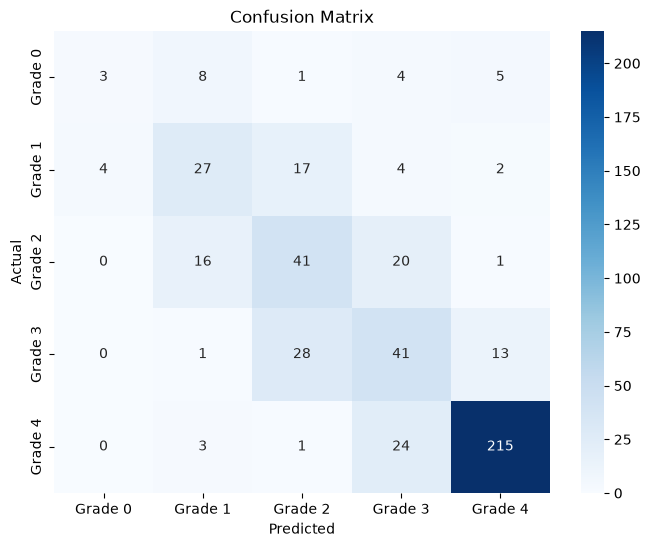

In [18]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Grade 0","Grade 1","Grade 2","Grade 3","Grade 4"],
    yticklabels=["Grade 0","Grade 1","Grade 2","Grade 3","Grade 4"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

### <i> Shap values

In [19]:
# Generate SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)
print("Shap values created")

Shap values created


### <i> Beeswarm plots

(479, 11, 5)


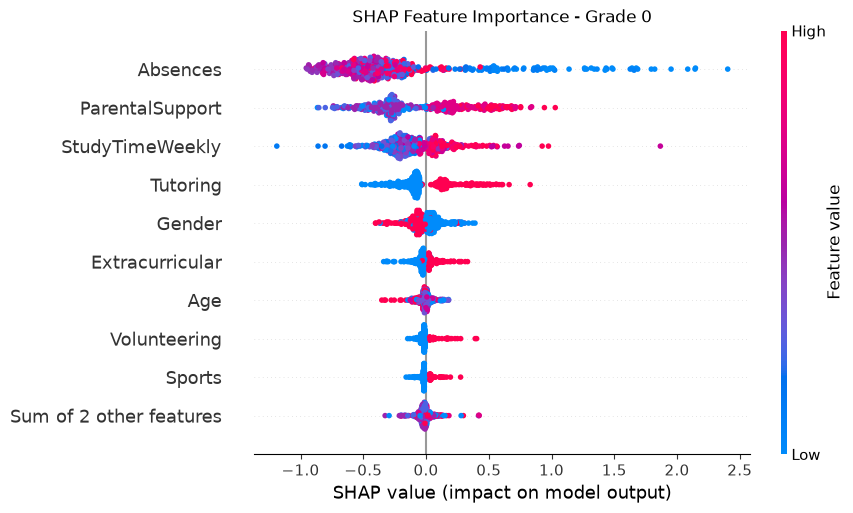

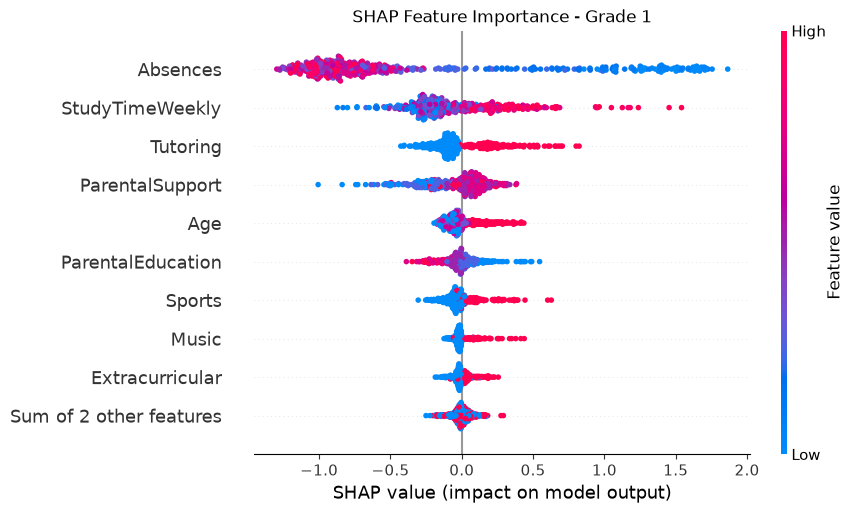

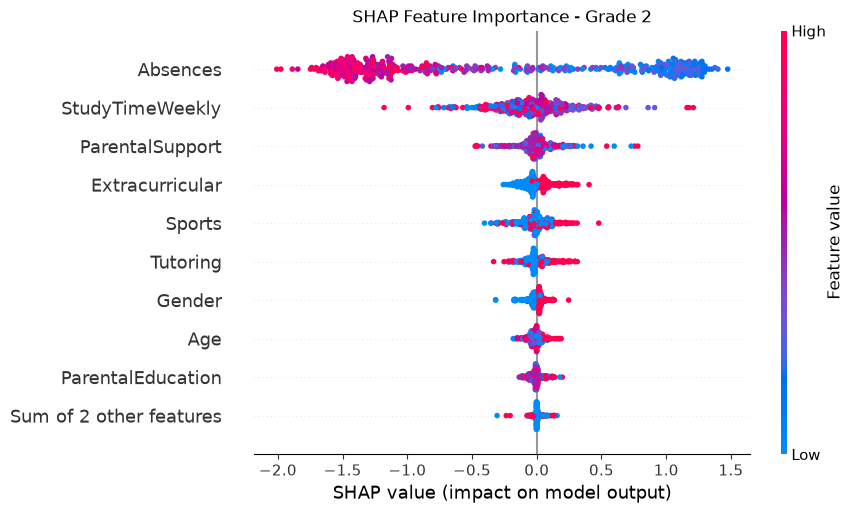

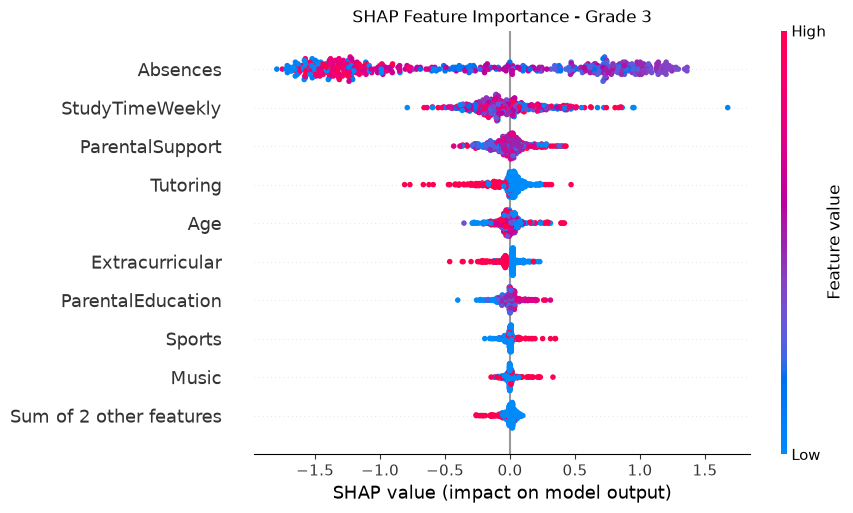

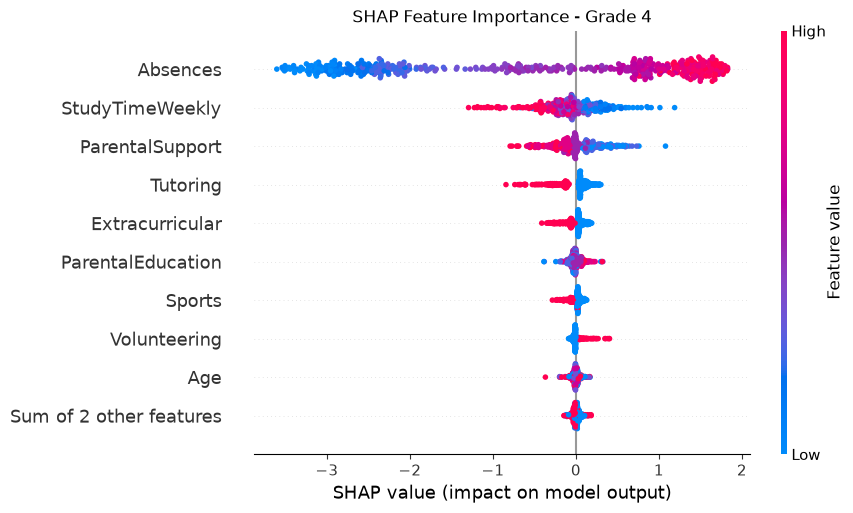

In [20]:
# Here we can tell we have a shape of 5, 
print(shap_values.shape)

# So we'll simply iterate through range(4) for each class.

for index in range(n_classes):

    # Select class 5
    shap_class = shap_values[:, :, index]

    plt.title(f"SHAP Feature Importance - Grade {index}")

    # Create cohorts from actual target labels
    shap.plots.beeswarm(shap_class)

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3>Observations</h3>

`music` has been taken out of the top features.

We are still seeing a lot of non-linear relationships. What is particularly surprising is that the new `AbsenceStudyInteraction` feature is also nonlinear? That is suspicious.

</div>

### <i> Cohort bar plot

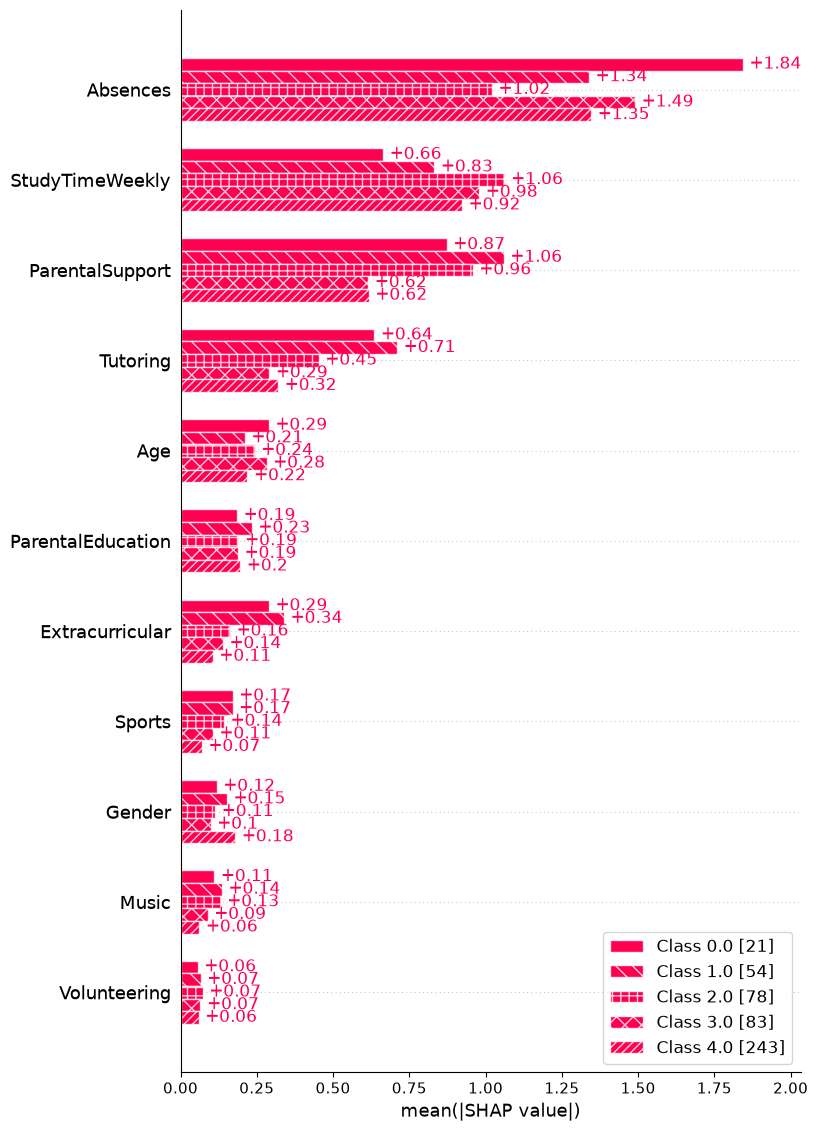

In [21]:
# Select class 0
shap_class = shap_values[:, :, 0]

# Create cohort labels
cohorts = [
    f"Class {value}" for value in y_test
]

# Calculate cohort importance
shap.plots.bar(cohort_values, max_display=X_test.shape[1])

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3>Observations</h3>

`Class 0` considers `Studytime_per_absence` to be unexplicably important. We might want to see if how many rows have class 0. That could be under-represented for a class.


</div>

### <i> Creating a dataframe with the worst prediction residuals

In [22]:
# Get the prediction error.
residuals = y_test - y_pred

# Create a copy of the test dataframe
predictions_df = X_test.copy()

# Add actual and predicted values
predictions_df["Actual"] = y_test
predictions_df["Predicted"] = y_pred

# Add residuals
predictions_df["Residual"] = residuals

# Sort by the worst predictions
worst_predictions = predictions_df.sort_values("Residual", ascending=False)
worst_predictions

,Age,Gender,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,Actual,Predicted,Residual
2388,17,0,1,7.583217,4,1,4,0,1,0,0,4.0,1,3.0
2267,18,1,2,7.598010,0,1,3,0,0,0,0,4.0,1,3.0
2197,18,0,2,17.472676,0,0,0,0,1,0,0,4.0,1,3.0
2268,15,0,3,9.518127,4,1,2,1,0,0,0,3.0,1,2.0
2238,18,0,4,9.356048,9,1,3,0,0,0,0,4.0,2,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2266,18,0,3,4.750322,16,0,3,0,0,0,0,0.0,4,-4.0
2284,16,0,1,13.673991,14,0,1,1,0,0,0,0.0,4,-4.0
2303,15,0,2,2.119118,13,1,3,1,0,0,0,0.0,4,-4.0
2194,15,0,2,15.615710,26,0,3,1,0,0,0,0.0,4,-4.0


### <i> Waterfall plot

In [23]:
# Find the index position in X_test from worst_predictions 
row_position = X_test.index.get_loc(2267)
print(f"The shap_value index is: {row_position}")

The shap_value index is: 50


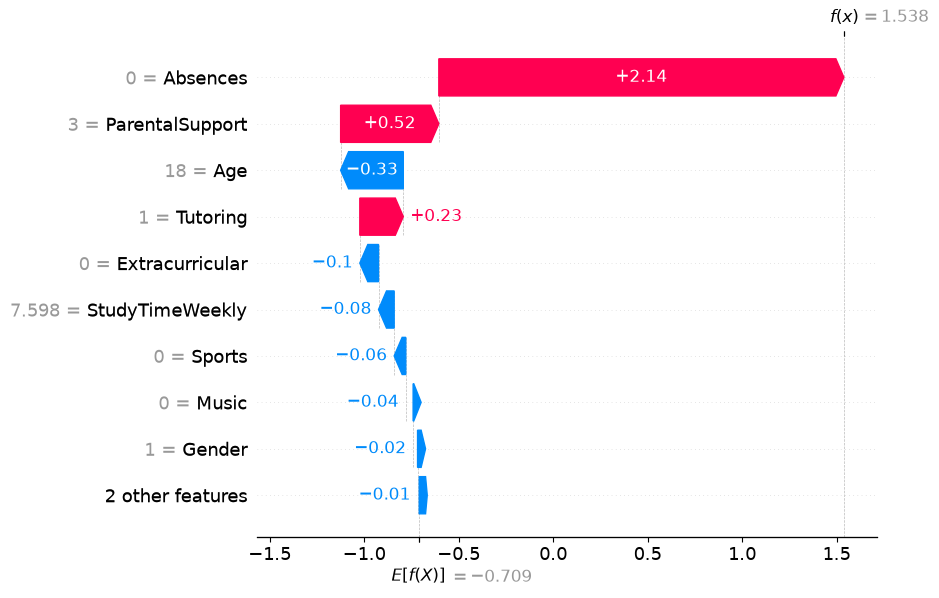

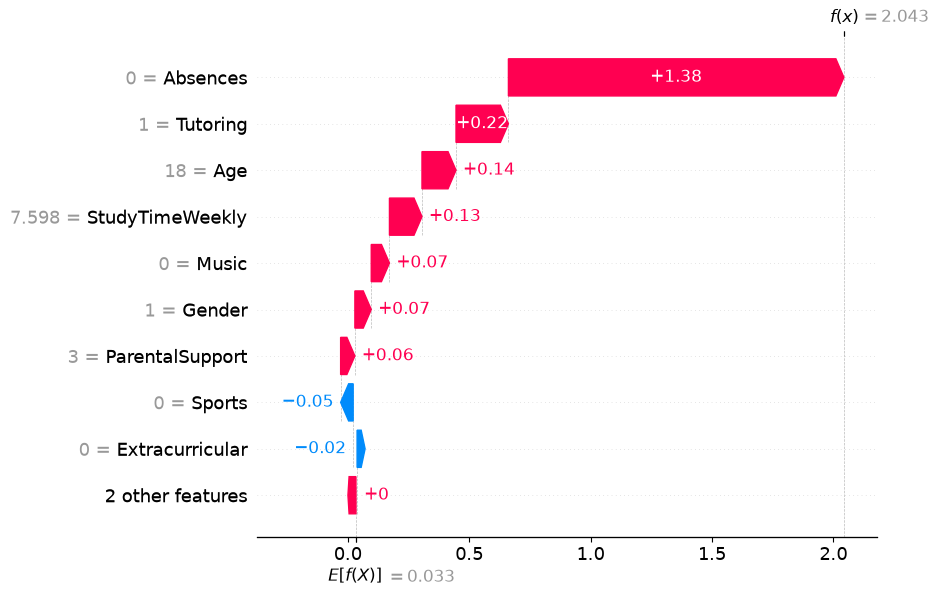

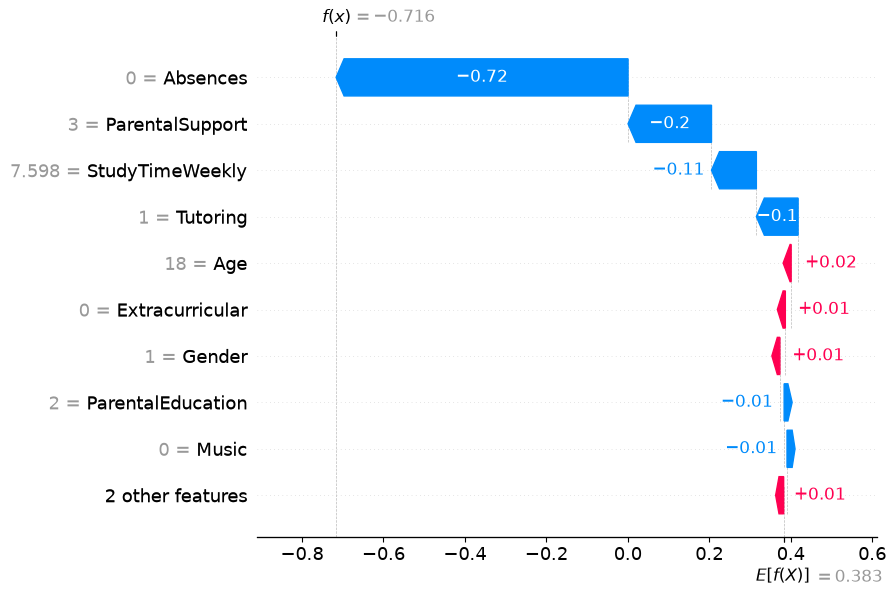

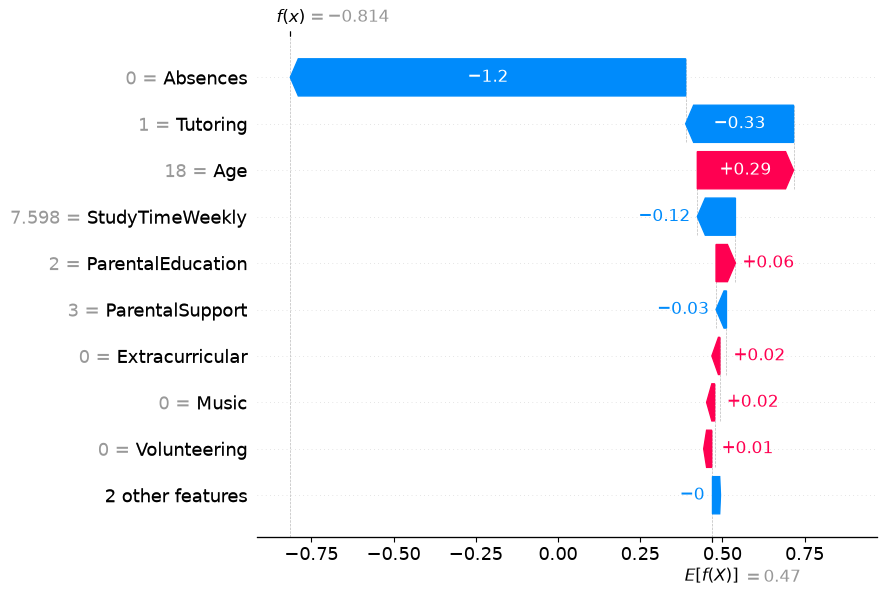

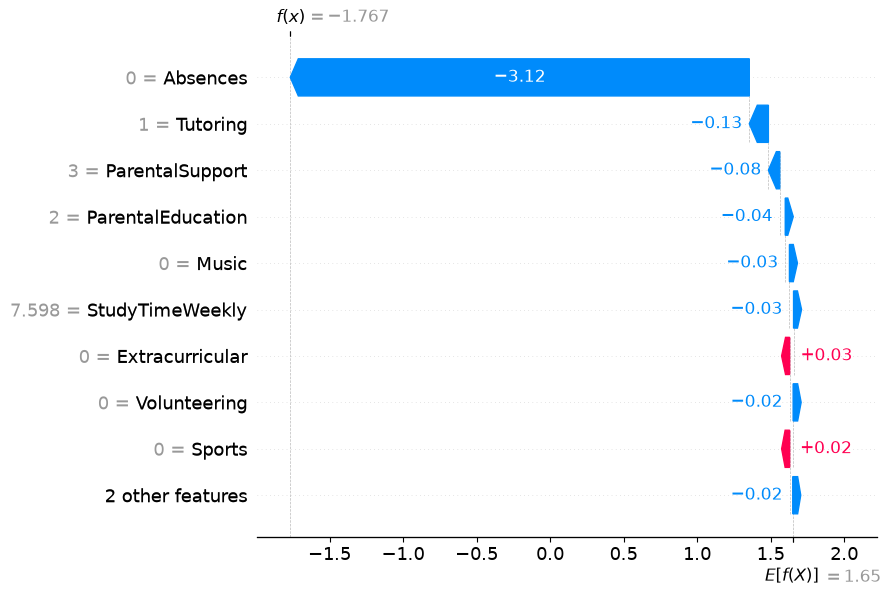

In [24]:
for index in range(n_classes):
    # Select class 0
    shap_class = shap_values[:, :, index]

    # Feel free to experiment!
    shap.plots.waterfall(shap_class[50])

### <i> Decision Plot

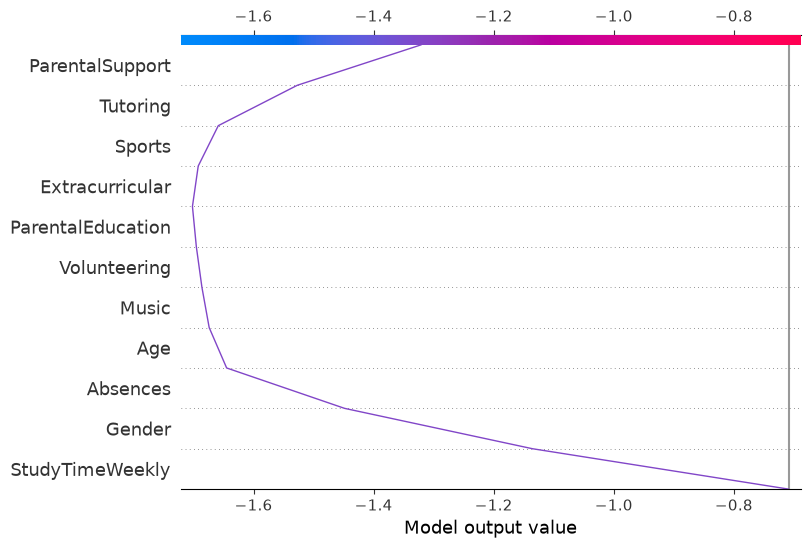

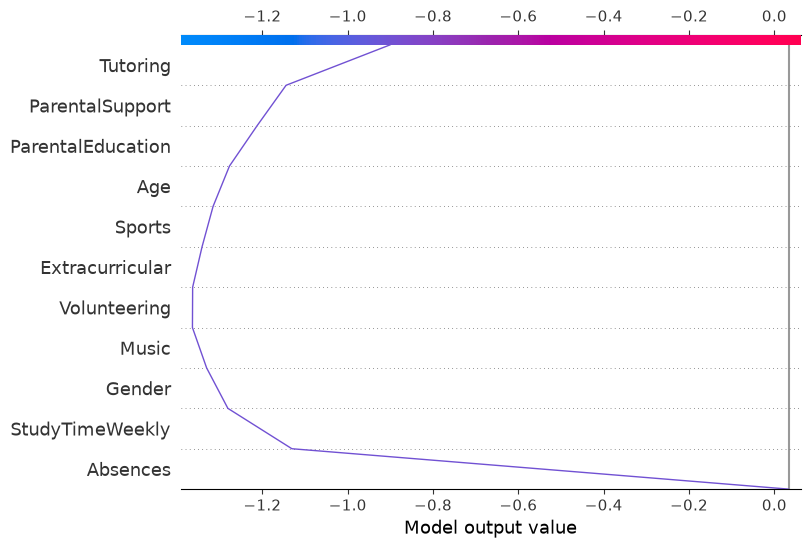

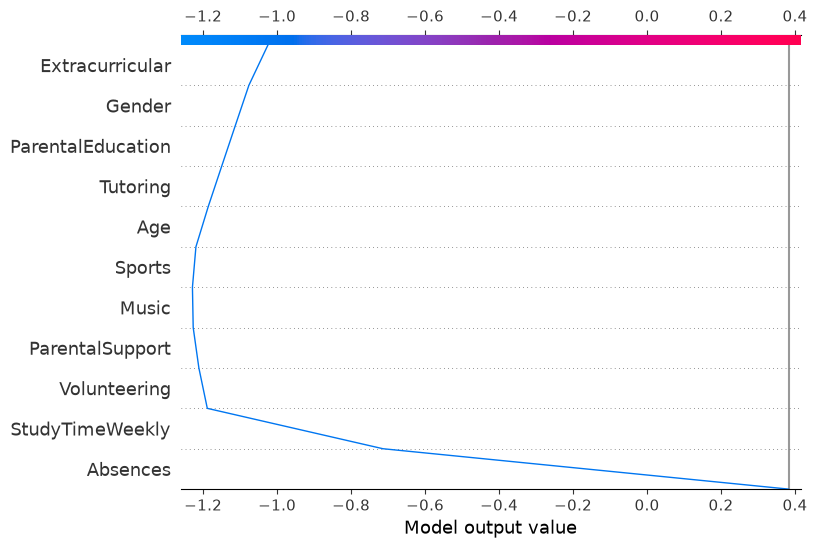

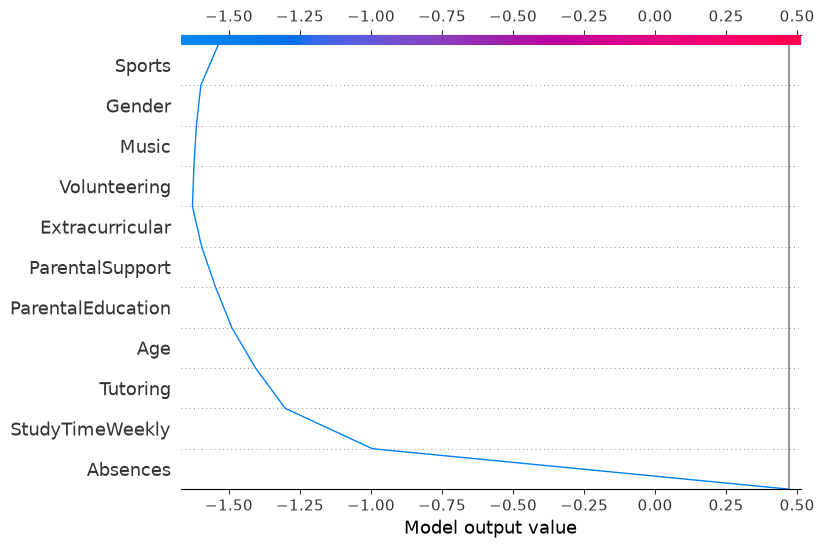

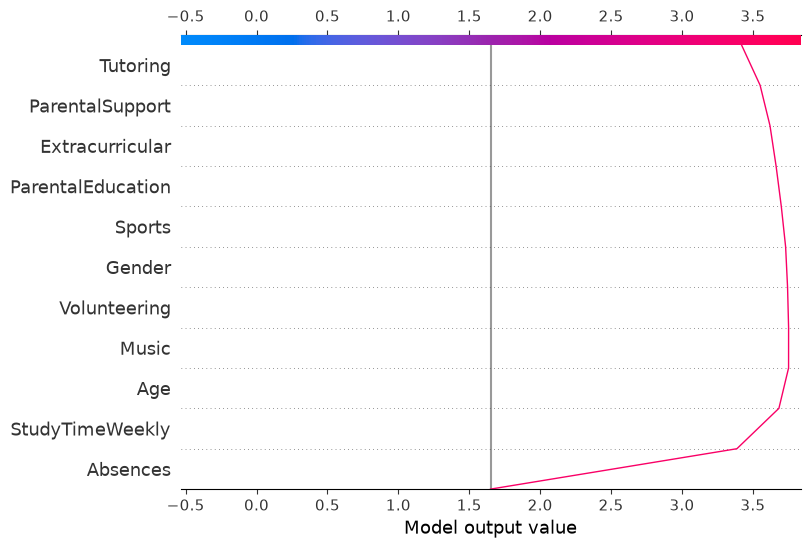

In [25]:
for index in range(n_classes):

    shap_class = shap_values[:, :, index]

    # Decision plot
    shap.decision_plot(
        shap_class.base_values[60],
        shap_class.values[60],
        feature_names=X_test.columns.tolist(),
        feature_order="hclust",
        show=True
    )

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>


<h3>Observations</h3>

We still need to check for multicollinearity, especially considering the new interaction features were created

`Sports` seems to be on-and-off for the worst case offenders and that leads me to believe that it might to be a useful column. Needs deeper investigation.

</div>